# Demand-to-Replenishment Engine
**Weekly demand forecasting → safety stock and reorder points → service level vs. inventory trade-off**

Portfolio project · Supply Chain / Data Analyst · Python (pandas, LightGBM) · Power BI-ready outputs

| | |
|---|---|
| Data | Store Item Demand Forecasting (Kaggle playground competition): 10 stores × 50 items, daily unit sales, 2013-01-01 to 2017-12-31 |
| Grain used | Weekly demand per store-item (500 series, 260 weeks) |
| Question | How much inventory does a retailer need to hold to reach a given service level, and how much of that depends on forecast quality? |

## 1. Business context

A retail chain replenishes its stores on a weekly cycle. Each week a planner decides, for every store-item, how much to order so that stock arrives before the shelf runs out. Two things drive that decision: the demand forecast over the *protection interval* (lead time plus review period) and a buffer for forecast error (safety stock).

Two failure modes pull in opposite directions. Too little buffer means lost sales and unhappy customers. Too much buffer ties up working capital and, for perishables, creates waste. The usual S&OP conversation is therefore not "what is the forecast?" but "what service level are we targeting, and what does it cost in inventory days?"

This project connects those pieces end to end: forecast → error distribution → safety stock / reorder point → simulation of the resulting policy on held-out weeks.

## 2. Problem statement and objectives

**Main question.** For a weekly-review replenishment process, how many inventory days are needed to hit a target service level, and how much of that inventory is attributable to forecast error?

**Supporting questions**
1. How predictable is weekly store-item demand, and which model is worth using over the planner's default (a moving average)?
2. Does forecast error scale with the protection interval the way textbook safety-stock formulas assume (√time)?
3. At equal realized service level, how many inventory days does a better forecast save?
4. How sensitive is the answer to supplier lead time (1, 2 or 3 weeks)?
5. Is it worth setting different service targets by ABC class?

**Deliverables of the engine:** per-series forecast, safety stock, reorder point and order-up-to level; a service-vs-inventory frontier; Power BI-ready tables.

## 3. KPI definitions

| KPI | Formula | Why it matters |
|---|---|---|
| WAPE | Σ\|actual − forecast\| / Σ actual | Volume-weighted forecast error; robust to small series |
| Bias | Σ(forecast − actual) / Σ actual | Systematic over (+) or under (−) forecasting |
| Safety stock | z × σ_PI | Buffer against forecast error over the protection interval |
| Reorder point | Forecast demand over lead time + safety stock | Stock level that triggers an order |
| Order-up-to level | Forecast over lead time + review period + safety stock | Target inventory position in a weekly review policy |
| Cycle service level (CSL) | Share of series-weeks with no stockout | Reliability of availability |
| Fill rate | 1 − lost units / demand units | Share of demand served from stock |
| Inventory days | Average on-hand units / average daily demand | Working-capital proxy (no unit costs in the data) |

σ_PI is the standard deviation of the forecast error cumulated over the protection interval, estimated empirically from out-of-sample errors rather than assumed from a √t rule.

## 4. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import data_processing as dp

RAW_FILE = ROOT / "data" / "raw" / "train.csv"
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
for d in (PROCESSED, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

GAP = 4            # features use only data at least 4 weeks before the target week
VAL_WEEKS = 26     # validation window: early stopping and sigma estimation
TEST_WEEKS = 52    # untouched hold-out used for policy simulation
FUTURE_WEEKS = 4   # weeks forecast beyond the last observed week
SEED = 7

NAVY, ORANGE, GREY, LIGHT = "#1F3A5F", "#C8553D", "#8A94A3", "#D9DEE5"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#333333", "xtick.color": "#333333",
    "ytick.color": "#333333", "axes.titleweight": "bold", "axes.titlesize": 11,
    "font.size": 9.5, "axes.grid": True, "grid.color": LIGHT, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})
METRICS = {}   # everything quoted in the report and slides is written here


def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()


def pct(x, d=1):
    return f"{x * 100:.{d}f}%"

## 5. Data loading and audit
The raw file is kept untouched in `data/raw/`. All transformations write to `data/processed/`.

In [2]:
raw = dp.load_raw(RAW_FILE)
checks = dp.validate_daily(raw)
audit = pd.DataFrame(
    [(name, "PASS" if ok else "FAIL", detail) for name, (ok, detail) in checks.items()],
    columns=["check", "result", "detail"],
)
display(audit)
assert all(ok for ok, _ in checks.values()), "Raw data failed validation"

print(f"rows: {len(raw):,} | stores: {raw.store.nunique()} | items: {raw['item'].nunique()} | "
      f"{raw.date.min():%Y-%m-%d} to {raw.date.max():%Y-%m-%d} ({raw.date.nunique()} days)")
print(raw["sales"].describe().round(1).to_string())
zero_rows = raw[raw["sales"] == 0]
print(f"\nzero-sales days: {len(zero_rows)}")
display(zero_rows)

,check,result,detail
0,no_null_values,PASS,0
1,unique_date_store_item,PASS,0
2,non_negative_sales,PASS,0
3,complete_daily_calendar,PASS,1826-1826 rows per series vs 1826 days
4,integer_sales,PASS,units are whole numbers


rows: 913,000 | stores: 10 | items: 50 | 2013-01-01 to 2017-12-31 (1826 days)
count    913000.0
mean         52.3
std          28.8
min           0.0
25%          30.0
50%          47.0
75%          70.0
max         231.0

zero-sales days: 1


,date,store,item,sales
462357,2014-01-15,6,4,0


**Audit result.** The file is structurally clean: no nulls, no duplicate keys, and every one of the 500 store-item series has all 1,826 days. That is unusual for real retail extracts, where missing days, returns and negative quantities are routine. The one zero-sales day is not enough to indicate intermittent demand, so intermittent-demand methods (Croston, etc.) are not needed here. Since the source is a competition dataset, there is also no information on prices, costs, lead times or stockouts, which limits what the inventory section can claim (see Limitations).

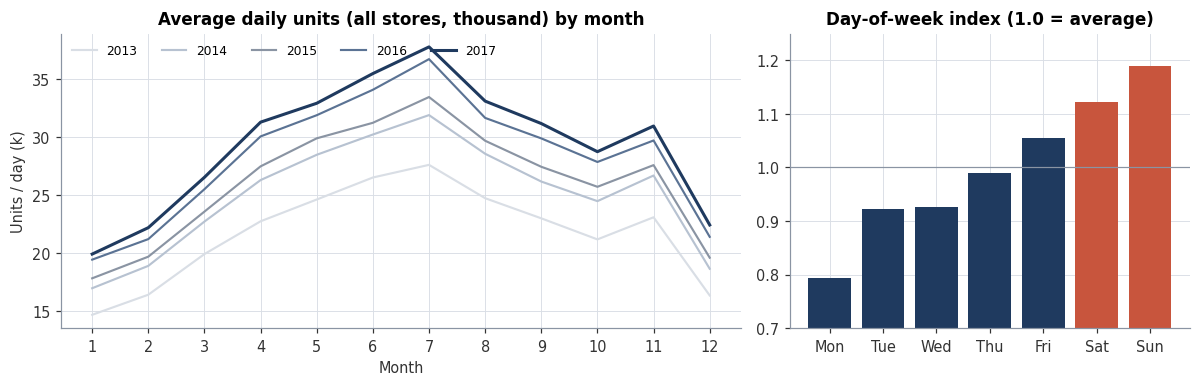

Units 2013 → 2017: 7,941,243 → 10,733,740 (35.2%)


In [3]:
daily_total = raw.groupby("date")["sales"].sum()
monthly = daily_total.groupby([daily_total.index.year.rename("year"), daily_total.index.month.rename("month")]).mean().unstack(0)
dow = daily_total.groupby(daily_total.index.dayofweek).mean()
dow_index = dow / dow.mean()
yearly = raw.groupby(raw.date.dt.year)["sales"].sum()
METRICS["yearly_units"] = {int(k): int(v) for k, v in yearly.items()}
METRICS["yearly_growth_2013_2017"] = float(yearly.loc[2017] / yearly.loc[2013] - 1)
METRICS["dow_index"] = {d: round(float(v), 3) for d, v in zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow_index)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.7, 1]})
cmap = [LIGHT, "#B7C2D1", GREY, "#5B7394", NAVY]
for color, year in zip(cmap, monthly.columns):
    axes[0].plot(monthly.index, monthly[year] / 1000, color=color, lw=2 if year == 2017 else 1.4, label=year)
axes[0].set(title="Average daily units (all stores, thousand) by month", xlabel="Month", ylabel="Units / day (k)")
axes[0].set_xticks(range(1, 13))
axes[0].legend(ncol=5, loc="upper left", fontsize=8)
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow_index, color=[NAVY] * 5 + [ORANGE] * 2)
axes[1].set(title="Day-of-week index (1.0 = average)", ylim=(0.7, 1.25))
axes[1].axhline(1, color=GREY, lw=0.8)
plt.tight_layout()
savefig("01_seasonality")
print(f"Units 2013 → 2017: {yearly.loc[2013]:,} → {yearly.loc[2017]:,} ({pct(METRICS['yearly_growth_2013_2017'])})")

Demand has a strong annual cycle (summer peak, winter trough), a clear weekend lift, and steady year-on-year growth. Those three facts shape the modelling choices: last-year demand will be a strong feature, and a model that only looks at the recent average will lag the seasonal swing.

### A pattern worth flagging before modelling
Seasonality on the first chart moves in steps. The check below removes the day-of-week effect from total daily units and compares the change at month boundaries with the change inside a month.

In [4]:
dow_adj = daily_total / daily_total.index.dayofweek.map(dow_index)
by_month = {m: g for m, g in dow_adj.groupby(dow_adj.index.to_period("M"))}
months = sorted(by_month)
within_cv = float(np.median([g.std() / g.mean() for g in by_month.values()]))
boundary_jump = float(np.mean([abs(by_month[b].iloc[:5].mean() / by_month[a].iloc[-5:].mean() - 1) for a, b in zip(months[:-1], months[1:])]))
mid_month_change = float(np.mean([abs(g.iloc[14:19].mean() / g.iloc[9:14].mean() - 1) for g in by_month.values()]))
METRICS["step_pattern"] = {"within_month_cv": within_cv, "month_boundary_jump": boundary_jump, "mid_month_change": mid_month_change,
                           "ratio": boundary_jump / mid_month_change}
print(f"Within-month variation of the day-of-week-adjusted daily total (median CV): {pct(within_cv, 2)}")
print(f"Average absolute change across a month boundary: {pct(boundary_jump)}  vs. {pct(mid_month_change, 2)} between two mid-month 5-day blocks "
      f"({boundary_jump / mid_month_change:.0f}×)")

Within-month variation of the day-of-week-adjusted daily total (median CV): 0.61%
Average absolute change across a month boundary: 11.3%  vs. 0.28% between two mid-month 5-day blocks (40×)


Demand is almost flat inside each month and jumps at month boundaries. Real store-level demand rarely behaves like this (promotions, weather and paydays create movement inside the month), which suggests the series were generated or heavily smoothed. I treat the dataset as a realistic *structure* for demonstrating the method, not as evidence about how a real retailer performs. This is repeated in the limitations, because it inflates forecast accuracy.

## 6. Weekly demand table
Replenishment decisions are weekly, so daily data is aggregated to Monday–Sunday weeks. The first week (6 days) is dropped as incomplete.

In [5]:
weekly = dp.to_weekly(raw)
weekly.to_csv(PROCESSED / "weekly_demand.csv", index=False)
P = weekly.pivot(index=["store", "item"], columns="week_start", values="demand")
series_idx = P.index
Y = P.to_numpy(dtype=float)
n_series, T = Y.shape
week_dates = pd.DatetimeIndex(P.columns)

test_start = T - TEST_WEEKS
val_start = test_start - VAL_WEEKS
val_weeks = np.arange(val_start, test_start)
test_weeks = np.arange(test_start, T)
print(f"{n_series} series × {T} weeks | validation {week_dates[val_start]:%Y-%m-%d}…{week_dates[test_start-1]:%Y-%m-%d} "
      f"| test {week_dates[test_start]:%Y-%m-%d}…{week_dates[-1]:%Y-%m-%d}")
print(f"minimum weekly demand in any series-week: {int(Y.min())}")
METRICS.update(n_series=int(n_series), n_weeks=int(T), n_daily_rows=int(len(raw)),
               val_period=[f"{week_dates[val_start]:%Y-%m-%d}", f"{week_dates[test_start-1]:%Y-%m-%d}"],
               test_period=[f"{week_dates[test_start]:%Y-%m-%d}", f"{week_dates[-1]:%Y-%m-%d}"],
               mean_weekly_demand=float(Y.mean()))

500 series × 260 weeks | validation 2016-07-04…2016-12-26 | test 2017-01-02…2017-12-25
minimum weekly demand in any series-week: 41


### ABC and predictability segmentation
ABC is based on pre-test volume only (weeks before the test window) so that nothing from the hold-out leaks into segment definitions. Predictability (X/Y/Z) is added later from validation forecast error, not from raw coefficient of variation, because raw CV mostly reflects seasonality that the forecast already explains.

In [6]:
pre_test_volume = Y[:, :test_start].sum(axis=1)
order = np.argsort(-pre_test_volume)
cum_share = np.cumsum(pre_test_volume[order]) / pre_test_volume.sum()
abc = np.empty(n_series, dtype=object)
abc[order] = np.where(cum_share <= 0.80, "A", np.where(cum_share <= 0.95, "B", "C"))
abc_summary = (pd.Series(pre_test_volume).groupby(abc).agg(series="size", volume_share=lambda s: s.sum() / pre_test_volume.sum()))
display(abc_summary.round(3))
METRICS["abc"] = {k: {"series": int(v["series"]), "volume_share": float(v["volume_share"])} for k, v in abc_summary.iterrows()}
cv_weekly = Y[:, :test_start].std(axis=1) / Y[:, :test_start].mean(axis=1)
print(f"weekly CV across series (incl. seasonality): median {np.median(cv_weekly):.2f}, range {cv_weekly.min():.2f}–{cv_weekly.max():.2f}")
print(f"mean weekly demand per series: min {Y.mean(1).min():.0f}, median {np.median(Y.mean(1)):.0f}, max {Y.mean(1).max():.0f}")

,series,volume_share
A,311,0.799
B,123,0.151
C,66,0.050


weekly CV across series (incl. seasonality): median 0.21, range 0.20–0.25
mean weekly demand per series: min 89, median 351, max 789


Volume is spread fairly evenly: the 500 series are all fast movers with a median of a few hundred units a week. The classical Pareto picture (a few A items carrying most of the volume) is weak here, which will matter when we test differentiated service targets.

## 7. Forecasting

**Design choices**
- **Direct, gap-4 features.** Every feature for week *t* uses data from week *t−4* or earlier. One model therefore serves any protection interval of up to four weeks without recursive forecasting, and its errors are slightly pessimistic for shorter horizons (a planner would normally have fresher data).
- **Global model.** One LightGBM model across all 500 series, with target and lag features scaled by each series' trailing 52-week mean so that series of different size share the same learning problem.
- **Three benchmarks.** (1) 13-week moving average, the typical planner default, using data up to last week (an advantage over the gap-4 model); (2) seasonal naive; (3) seasonal naive × recent year-on-year growth, a strong simple method.
- **Time-ordered split.** Train → validation (26 weeks, early stopping and σ estimation) → test (52 weeks, never used for tuning).

In [7]:
def build_features(y_ext):
    """Feature cube (series, weeks, features), scale matrix and scaled target. y_ext may end with NaN future weeks."""
    frame = pd.DataFrame(y_ext.T)
    lagged = frame.shift(GAP)
    scale = lagged.rolling(52).mean().T.to_numpy()
    feats = {f"lag{k}": frame.shift(k).T.to_numpy() / scale for k in (4, 5, 6, 8, 13, 26, 51, 52, 53)}
    r13 = lagged.rolling(13).mean()
    feats["roll4"] = lagged.rolling(4).mean().T.to_numpy() / scale
    feats["roll13"] = r13.T.to_numpy() / scale
    feats["yoy_growth"] = (r13 / r13.shift(52)).T.to_numpy()
    feats["same_week_ly"] = (feats["lag51"] + feats["lag52"] + feats["lag53"]) / 3
    n, t_ext = y_ext.shape
    dates = pd.date_range(week_dates[0], periods=t_ext, freq="7D")
    feats["week_of_year"] = np.tile(dates.isocalendar().week.to_numpy(float), (n, 1))
    feats["month"] = np.tile(dates.month.to_numpy(float), (n, 1))
    feats["store"] = np.repeat(series_idx.get_level_values("store").to_numpy(float)[:, None], t_ext, axis=1)
    feats["item"] = np.repeat(series_idx.get_level_values("item").to_numpy(float)[:, None], t_ext, axis=1)
    names = list(feats)
    return np.stack([feats[k] for k in names], axis=-1), names, scale, y_ext / scale


Y_ext = np.hstack([Y, np.full((n_series, FUTURE_WEEKS), np.nan)])
T_ext = Y_ext.shape[1]
ext_dates = pd.date_range(week_dates[0], periods=T_ext, freq="7D")
X, FEATURES, SCALE, TARGET = build_features(Y_ext)
CATEGORICAL = ["store", "item"]
numeric_cols = [i for i, f in enumerate(FEATURES) if f not in CATEGORICAL]


def gather(weeks, with_target=True):
    x = X[:, weeks, :].reshape(-1, len(FEATURES))
    ok = ~np.isnan(x[:, numeric_cols]).any(axis=1)
    y = TARGET[:, weeks].reshape(-1)
    if with_target:
        ok &= ~np.isnan(y)
    return x[ok], y[ok]


LGB_PARAMS = dict(objective="l2", learning_rate=0.05, num_leaves=31, min_data_in_leaf=50, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=1)


def train_lgb(train_weeks, n_rounds=None, valid_weeks=None):
    xt, yt = gather(train_weeks)
    ds = lgb.Dataset(xt, yt, feature_name=FEATURES, categorical_feature=CATEGORICAL)
    if valid_weeks is not None:
        xv, yv = gather(valid_weeks)
        dv = lgb.Dataset(xv, yv, reference=ds)
        return lgb.train(LGB_PARAMS, ds, 2000, valid_sets=[dv], callbacks=[lgb.early_stopping(50, verbose=False)])
    return lgb.train(LGB_PARAMS, ds, n_rounds)


def predict_weeks(model, weeks, num_iteration=None):
    x = X[:, weeks, :].reshape(-1, len(FEATURES))
    return model.predict(x, num_iteration=num_iteration).reshape(n_series, len(weeks)) * SCALE[:, weeks]


complete = ~np.isnan(X[:, :, numeric_cols]).any(axis=2).any(axis=0)   # weeks where every series has all lag features
first_train_week = int(np.argmax(complete))
train_a = np.arange(first_train_week, val_start)
model_a = train_lgb(train_a, valid_weeks=val_weeks)
best_rounds = model_a.best_iteration
model_b = train_lgb(np.arange(first_train_week, test_start), n_rounds=best_rounds)
print(f"training weeks {first_train_week}-{val_start-1} ({len(train_a)} weeks × {n_series} series), "
      f"early-stopped at {best_rounds} rounds")

F = {name: np.full((n_series, T_ext), np.nan) for name in ("LightGBM", "Seasonal naive × YoY growth", "Seasonal naive", "13-wk moving average")}
F["LightGBM"][:, val_weeks] = predict_weeks(model_a, val_weeks, best_rounds)          # validation: model never saw these weeks
F["LightGBM"][:, np.arange(test_start, T_ext)] = predict_weeks(model_b, np.arange(test_start, T_ext))  # test + future
frame_y = pd.DataFrame(Y_ext.T)
r13_gap = frame_y.shift(GAP).rolling(13).mean()
F["Seasonal naive"] = frame_y.shift(52).T.to_numpy()
F["Seasonal naive × YoY growth"] = (frame_y.shift(52) * (r13_gap / r13_gap.shift(52))).T.to_numpy()
F["13-wk moving average"] = frame_y.shift(1).rolling(13).mean().T.to_numpy()

training weeks 68-181 (114 weeks × 500 series), early-stopped at 80 rounds


In [8]:
def accuracy(forecast, weeks, series_mask=None):
    m = np.ones(n_series, bool) if series_mask is None else series_mask
    a, f = Y[m][:, weeks], forecast[m][:, weeks]
    return {"WAPE": np.abs(a - f).sum() / a.sum(), "Bias": (f - a).sum() / a.sum()}


rows = []
for name, fc in F.items():
    v, t = accuracy(fc, val_weeks), accuracy(fc, test_weeks)
    rows.append({"method": name, "val WAPE": v["WAPE"], "val bias": v["Bias"], "test WAPE": t["WAPE"], "test bias": t["Bias"]})
acc = pd.DataFrame(rows).set_index("method").sort_values("test WAPE")
display(acc.style.format("{:.2%}"))
METRICS["accuracy"] = {k: {c: float(v) for c, v in r.items()} for k, r in acc.iterrows()}
best_baseline = acc.drop(index="LightGBM")["test WAPE"].idxmin()
METRICS["fva_vs_best_baseline"] = float(1 - acc.loc["LightGBM", "test WAPE"] / acc.loc[best_baseline, "test WAPE"])
METRICS["fva_vs_ma13"] = float(1 - acc.loc["LightGBM", "test WAPE"] / acc.loc["13-wk moving average", "test WAPE"])
METRICS["best_baseline"] = best_baseline
print(f"LightGBM test WAPE is {pct(METRICS['fva_vs_best_baseline'])} lower than the best baseline ({best_baseline}) "
      f"and {pct(METRICS['fva_vs_ma13'])} lower than the 13-week moving average.")

,val WAPE,val bias,test WAPE,test bias
method,,,,
LightGBM,4.45%,0.36%,4.32%,1.49%
Seasonal naive × YoY growth,5.92%,-0.45%,5.93%,0.62%
Seasonal naive,9.01%,-8.17%,6.22%,-3.67%
13-wk moving average,12.11%,7.78%,13.86%,-0.52%


LightGBM test WAPE is 27.1% lower than the best baseline (Seasonal naive × YoY growth) and 68.8% lower than the 13-week moving average.


,WAPE,Bias
A,3.95%,1.47%
B,5.45%,1.53%
C,6.79%,1.67%


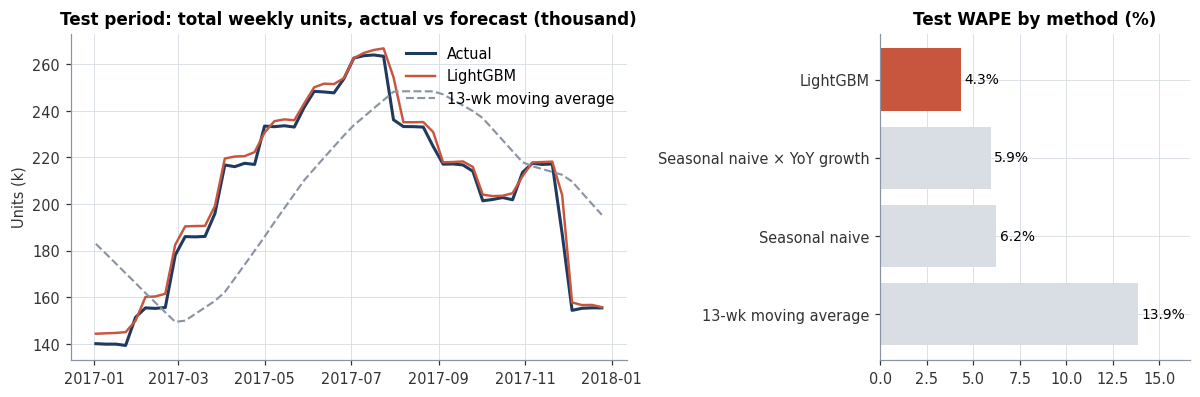

In [9]:
by_class = pd.DataFrame({c: accuracy(F["LightGBM"], test_weeks, abc == c) for c in "ABC"}).T
display(by_class.style.format("{:.2%}"))
METRICS["lgbm_test_wape_by_abc"] = {c: float(by_class.loc[c, "WAPE"]) for c in "ABC"}

gain = pd.Series(model_b.feature_importance("gain"), index=FEATURES)
gain = (gain / gain.sum()).sort_values(ascending=False)
METRICS["top_features"] = {k: float(v) for k, v in gain.head(5).items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), gridspec_kw={"width_ratios": [1.8, 1]})
tot_a = Y[:, test_weeks].sum(0) / 1000
axes[0].plot(week_dates[test_weeks], tot_a, color=NAVY, lw=2, label="Actual")
axes[0].plot(week_dates[test_weeks], F["LightGBM"][:, test_weeks].sum(0) / 1000, color=ORANGE, lw=1.6, label="LightGBM")
axes[0].plot(week_dates[test_weeks], F["13-wk moving average"][:, test_weeks].sum(0) / 1000, color=GREY, lw=1.4, ls="--", label="13-wk moving average")
axes[0].set(title="Test period: total weekly units, actual vs forecast (thousand)", ylabel="Units (k)")
axes[0].legend(loc="upper right")
order_plot = acc.sort_values("test WAPE", ascending=False)
colors = [ORANGE if m == "LightGBM" else LIGHT for m in order_plot.index]
axes[1].barh(order_plot.index, order_plot["test WAPE"] * 100, color=colors)
for i, v in enumerate(order_plot["test WAPE"] * 100):
    axes[1].text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
axes[1].set(title="Test WAPE by method (%)", xlim=(0, order_plot["test WAPE"].max() * 100 * 1.2))
plt.tight_layout()
savefig("02_forecast_accuracy")

### What the accuracy numbers do and do not say
The error floor on this dataset is low. Aggregating to weekly store-item level smooths day-to-day noise, and the annual pattern repeats closely year after year, which is why last year's same-week demand dominates the feature importance. Real retail demand with promotions, price changes, weather and stockouts would produce larger errors, so absolute WAPE and the inventory days derived from it should be treated as a best case. The comparison between methods is the more transferable result.

## 8. From forecast error to safety stock

Safety stock needs the standard deviation of forecast error **over the protection interval** (lead time *L* + review period *R* = 1 week). A common shortcut is σ₁·√(L+R), which assumes weekly errors are independent. Instead of assuming, I measure it: for each series, errors are cumulated over every rolling (L+1)-week window in the validation period and the standard deviation is taken directly.

In [10]:
def interval_forecast(method, L):
    """Forecast of demand over weeks t..t+L, evaluated at ordering week t."""
    fc = F[method]
    if method == "13-wk moving average":      # flat forecast built from data up to week t-1
        return lambda t: (L + 1) * fc[:, t]
    return lambda t: fc[:, t:t + L + 1].sum(axis=1)


def interval_errors(method, L, origins):
    fsum = interval_forecast(method, L)
    return np.array([Y[:, t:t + L + 1].sum(axis=1) - fsum(t) for t in origins])


def sigma_interval(method, L, weeks=val_weeks):
    origins = range(weeks[0], weeks[-1] + 1 - L)
    return interval_errors(method, L, origins).std(axis=0, ddof=1)


rows = []
for L in (1, 2, 3):
    for method in ("LightGBM", "13-wk moving average"):
        weekly_err = Y[:, val_weeks] - F[method][:, val_weeks]
        sigma_1 = weekly_err.std(axis=1, ddof=1)
        sigma_pi = sigma_interval(method, L)
        rows.append({"lead time (wk)": L, "method": method,
                     "mean σ weekly": sigma_1.mean(), "mean σ interval": sigma_pi.mean(),
                     "√(L+1) rule": (sigma_1 * np.sqrt(L + 1)).mean(),
                     "empirical / √ rule": (sigma_pi / (sigma_1 * np.sqrt(L + 1))).mean()})
sigma_check = pd.DataFrame(rows)
display(sigma_check.round(2))
METRICS["sigma_check"] = sigma_check.round(3).to_dict("records")

err_test = Y[:, test_weeks] - F["LightGBM"][:, test_weeks]
lag1_corr = np.mean([np.corrcoef(e[:-1], e[1:])[0, 1] for e in err_test])
METRICS["lgbm_error_lag1_autocorr"] = float(lag1_corr)
print(f"Average lag-1 autocorrelation of weekly LightGBM errors (test): {lag1_corr:.2f}")

,lead time (wk),method,mean σ weekly,mean σ interval,√(L+1) rule,empirical / √ rule
0,1,LightGBM,23.01,32.92,32.54,1.01
1,1,13-wk moving average,49.14,92.23,69.50,1.31
2,2,LightGBM,23.01,40.08,39.85,1.00
3,2,13-wk moving average,49.14,131.08,85.12,1.52
4,3,LightGBM,23.01,45.95,46.02,0.99
5,3,13-wk moving average,49.14,162.73,98.29,1.63


Average lag-1 autocorrelation of weekly LightGBM errors (test): 0.02


If the empirical-to-√ ratio is above 1, errors are positively autocorrelated and the √ rule would understate the buffer; below 1 it would overstate it. The table is used to decide whether the textbook shortcut is acceptable here. The simulation below uses the empirical interval σ in all cases.

### Predictability segments
Series are split into thirds by relative forecast error on the validation window (σ₁ divided by mean demand). X = most predictable, Z = least.

In [11]:
rel_sigma = (Y[:, val_weeks] - F["LightGBM"][:, val_weeks]).std(axis=1, ddof=1) / Y[:, val_weeks].mean(axis=1)
xyz = pd.qcut(rel_sigma, 3, labels=["X", "Y", "Z"]).astype(str)
seg = pd.crosstab(pd.Series(abc, name="ABC"), pd.Series(xyz, name="XYZ"))
display(seg)
print(f"relative weekly error σ/mean: X ≤ {rel_sigma[xyz=='X'].max():.3f}, Y ≤ {rel_sigma[xyz=='Y'].max():.3f}, Z up to {rel_sigma.max():.3f}")
METRICS["rel_sigma_range"] = [float(rel_sigma.min()), float(rel_sigma.max())]

XYZ,X,Y,Z
ABC,,,
A,164,120,27
B,3,43,77
C,0,3,63


relative weekly error σ/mean: X ≤ 0.052, Y ≤ 0.067, Z up to 0.127


## 9. Replenishment policy simulator

**Policy:** weekly review, order-up-to. At the start of week *t*, receive arriving stock, then order up to  
`S_t = forecast demand over weeks t…t+L + z·σ_interval`  
and the order arrives at the start of week *t+L*. Unmet demand is lost (retail shelf, no backorders). The simulation runs over the 52 untouched test weeks using actual demand, with σ estimated from the *validation* window only, so the safety stock is set without knowing the test outcomes.

The first L+1 weeks are treated as warm-up and excluded from metrics.

In [12]:
def simulate(method, L, z, sigma=None, weeks=test_weeks, return_series=False):
    z = np.broadcast_to(np.asarray(z, float), (n_series,))
    sigma = sigma_interval(method, L) if sigma is None else sigma
    fsum = interval_forecast(method, L)
    on_hand = np.maximum(fsum(weeks[0]) + z * sigma, 0)
    pipeline = np.zeros((n_series, L))
    lost = np.zeros(n_series); demand = np.zeros(n_series); stock = np.zeros(n_series)
    stockout_weeks = np.zeros(n_series); counted = 0
    for t in weeks:
        on_hand = on_hand + pipeline[:, 0]
        pipeline = np.hstack([pipeline[:, 1:], np.zeros((n_series, 1))])
        if t <= weeks[-1] - L:                       # an order placed later would not arrive in the window
            target = np.maximum(fsum(t) + z * sigma, 0)
            pipeline[:, L - 1] += np.maximum(target - on_hand - pipeline.sum(axis=1), 0)
        start = on_hand.copy()
        sold = np.minimum(on_hand, Y[:, t])
        on_hand = on_hand - sold
        if t >= weeks[0] + L + 1:
            lost += Y[:, t] - sold; demand += Y[:, t]
            stock += (start + on_hand) / 2
            stockout_weeks += (Y[:, t] - sold) > 0
            counted += 1
    out = {"fill_rate": 1 - lost.sum() / demand.sum(), "csl": 1 - stockout_weeks.sum() / (counted * n_series),
           "inventory_days": (stock.sum() / counted) / (demand.sum() / counted) * 7}
    if return_series:
        out.update(lost=lost, demand=demand, avg_stock=stock / counted, stockout_weeks=stockout_weeks, weeks_counted=counted)
    return out


# Sanity tests for the simulator. A previous version of this cell had an off-by-one in the pipeline index
# (lead time acted as L+1); these checks are there so that cannot go unnoticed again.
def check_simulator():
    # 1. Huge safety stock -> no lost sales
    assert simulate("LightGBM", 1, 8.0)["fill_rate"] > 0.99999
    # 2. Zero safety stock with a 1-week lead time must hold roughly one cycle (> 3 days) of stock, not ~2
    base = simulate("LightGBM", 1, 0.0)
    assert 3.0 < base["inventory_days"] < 5.0, base
    # 3. Service must be monotone in z and longer lead time must need more stock at equal z
    s = [simulate("LightGBM", 2, z)["csl"] for z in (0, 1, 2, 3)]
    assert all(b >= a for a, b in zip(s, s[1:])), s
    assert simulate("LightGBM", 2, 1.0)["inventory_days"] > simulate("LightGBM", 1, 1.0)["inventory_days"]
    # 4. Perfect foresight forecast with z=0 serves all demand
    F["Oracle"] = np.where(np.isnan(Y_ext), np.nan, Y_ext)
    assert simulate("Oracle", 1, 0.0, sigma=np.zeros(n_series))["fill_rate"] > 0.9999
    del F["Oracle"]
    return True


print("simulator checks passed:", check_simulator())

simulator checks passed: True


In [13]:
Z_GRID = np.round(np.arange(-0.5, 3.51, 0.25), 2)
METHODS = ["LightGBM", "Seasonal naive × YoY growth", "13-wk moving average"]
frontier = pd.DataFrame([
    {"method": m, "lead_time_weeks": L, "z": z, **simulate(m, L, z)}
    for L in (1, 2, 3) for m in METHODS for z in Z_GRID
])
frontier.to_csv(PROCESSED / "service_frontier.csv", index=False)


def inventory_days_at(method, L, csl_target):
    f = frontier[(frontier.method == method) & (frontier.lead_time_weeks == L)].sort_values("z")
    csl = np.maximum.accumulate(f["csl"].to_numpy())
    return float(np.interp(csl_target, csl, f["inventory_days"].to_numpy()))


def z_at(method, L, csl_target):
    f = frontier[(frontier.method == method) & (frontier.lead_time_weeks == L)].sort_values("z")
    return float(np.interp(csl_target, np.maximum.accumulate(f["csl"].to_numpy()), f["z"].to_numpy()))


rows = []
for L in (1, 2, 3):
    for target in (0.90, 0.95, 0.98):
        r = {"lead time (wk)": L, "realized CSL": target}
        for m in METHODS:
            r[m] = inventory_days_at(m, L, target)
        r["saving vs 13-wk MA"] = 1 - r["LightGBM"] / r["13-wk moving average"]
        r["saving vs best simple"] = 1 - r["LightGBM"] / r["Seasonal naive × YoY growth"]
        rows.append(r)
equal_service = pd.DataFrame(rows)
display(equal_service.style.format({"realized CSL": "{:.0%}", **{m: "{:.2f}" for m in METHODS},
                                    "saving vs 13-wk MA": "{:.1%}", "saving vs best simple": "{:.1%}"}))
METRICS["equal_service"] = equal_service.round(4).to_dict("records")

,lead time (wk),realized CSL,LightGBM,Seasonal naive × YoY growth,13-wk moving average,saving vs 13-wk MA,saving vs best simple
0,1,90%,4.17,4.48,6.24,33.1%,6.8%
1,1,95%,4.38,4.77,6.68,34.4%,8.2%
2,1,98%,4.66,5.14,7.15,34.8%,9.4%
3,2,90%,4.31,4.69,7.53,42.8%,8.1%
4,2,95%,4.57,5.09,8.20,44.3%,10.2%
5,2,98%,4.91,5.58,8.89,44.7%,12.0%
6,3,90%,4.40,4.86,8.90,50.5%,9.4%
7,3,95%,4.72,5.33,9.74,51.6%,11.5%
8,3,98%,5.13,5.96,10.61,51.7%,13.9%


In [14]:
# Inventory days that exist even with no safety factor (z = 0, LightGBM forecast): mainly cycle stock plus the forecast-driven order-up-to level.
base_days = {L: float(frontier[(frontier.method == "LightGBM") & (frontier.lead_time_weeks == L) & (frontier.z == 0)]["inventory_days"].iloc[0]) for L in (1, 2, 3)}
buffer_days = pd.DataFrame({L: {m: inventory_days_at(m, L, 0.95) - base_days[L] for m in METHODS} for L in (1, 2, 3)}).T
buffer_days.index.name = "lead time (wk)"
display(buffer_days.round(2))
METRICS["base_days_z0"] = base_days
METRICS["buffer_days_csl95"] = {int(L): {m: float(v) for m, v in r.items()} for L, r in buffer_days.iterrows()}

,LightGBM,Seasonal naive × YoY growth,13-wk moving average
lead time (wk),,,
1,0.56,0.95,2.86
2,0.60,1.12,4.23
3,0.62,1.23,5.64


"Inventory days at realized CSL" is the fair comparison: each method gets the z that delivers the same *measured* service on the test weeks, so a method cannot look cheap by quietly under-serving. The next table shows how far the nominal target (z from the normal distribution) is from what was realized.

In [15]:
cal_rows = []
for L in (1, 2):
    for nominal in (0.90, 0.95, 0.98):
        for m in METHODS:
            r = simulate(m, L, norm.ppf(nominal))
            cal_rows.append({"lead time (wk)": L, "method": m, "nominal CSL": nominal, "realized CSL": r["csl"],
                             "fill rate": r["fill_rate"], "inventory days": r["inventory_days"]})
calibration = pd.DataFrame(cal_rows)
display(calibration.pivot_table(index=["lead time (wk)", "nominal CSL"], columns="method", values="realized CSL").style.format("{:.1%}"))
METRICS["calibration"] = calibration.round(4).to_dict("records")

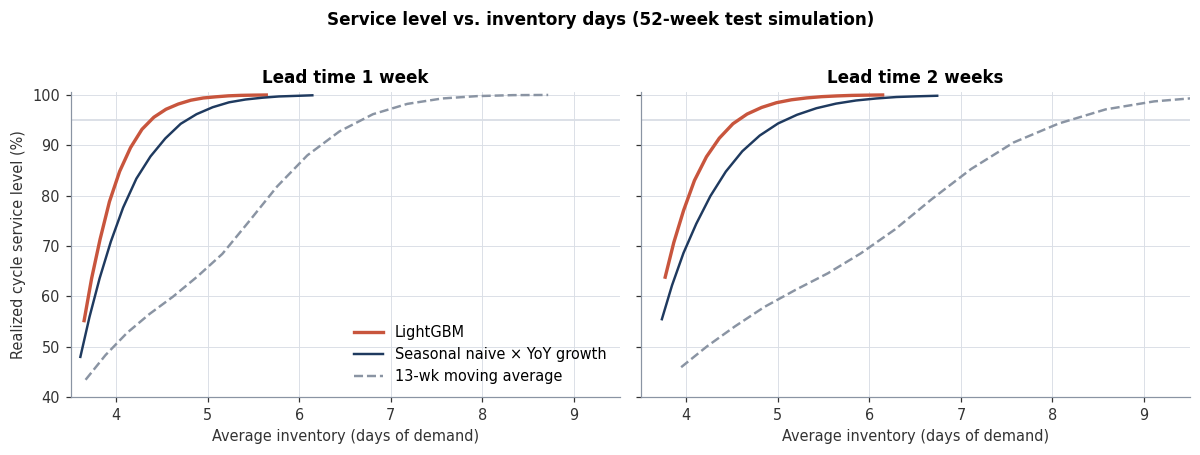

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
styles = {"LightGBM": (ORANGE, "-", 2.2), "Seasonal naive × YoY growth": (NAVY, "-", 1.6), "13-wk moving average": (GREY, "--", 1.6)}
for ax, L in zip(axes, (1, 2)):
    for m, (c, ls, lw) in styles.items():
        f = frontier[(frontier.method == m) & (frontier.lead_time_weeks == L)].sort_values("z")
        ax.plot(f["inventory_days"], f["csl"] * 100, color=c, ls=ls, lw=lw, label=m)
    ax.axhline(95, color=LIGHT, lw=1.2, zorder=0)
    ax.set(title=f"Lead time {L} week{'s' if L > 1 else ''}", xlabel="Average inventory (days of demand)", xlim=(3.5, 9.5), ylim=(40, 100.5))
axes[0].set_ylabel("Realized cycle service level (%)")
axes[0].legend(loc="lower right")
fig.suptitle("Service level vs. inventory days (52-week test simulation)", fontweight="bold", y=1.02, fontsize=11)
plt.tight_layout()
savefig("03_service_frontier")

## 10. Lead-time sensitivity and differentiated service targets

Lead time is not in the dataset, so it is treated as a scenario variable rather than a fact. The table above already shows 1, 2 and 3 weeks. Next: does an ABC-differentiated target (A 98% / B 95% / C 90%) beat a uniform 95% target? Targets are nominal z-values applied to the LightGBM policy, lead time 1 week.

In [17]:
def tiered_z(targets):
    return np.array([norm.ppf(targets[c]) for c in abc])


policies = {"Uniform 95%": tiered_z({"A": .95, "B": .95, "C": .95}),
            "Tiered A98 / B95 / C90": tiered_z({"A": .98, "B": .95, "C": .90}),
            "Uniform 90%": tiered_z({"A": .90, "B": .90, "C": .90})}
rows = []
for name, z in policies.items():
    r = simulate("LightGBM", 1, z, return_series=True)
    row = {"policy": name, "inventory days": r["inventory_days"], "fill rate": r["fill_rate"], "CSL": r["csl"]}
    for c in "ABC":
        m = abc == c
        row[f"CSL {c}"] = 1 - r["stockout_weeks"][m].sum() / (r["weeks_counted"] * m.sum())
    rows.append(row)
tier_table = pd.DataFrame(rows).set_index("policy")
display(tier_table.style.format({"inventory days": "{:.2f}", "fill rate": "{:.2%}", **{c: "{:.1%}" for c in ["CSL", "CSL A", "CSL B", "CSL C"]}}))
METRICS["tiering"] = {k: {c: float(v) for c, v in r.items()} for k, r in tier_table.iterrows()}

,inventory days,fill rate,CSL,CSL A,CSL B,CSL C
policy,,,,,,
Uniform 95%,4.62,99.94%,97.8%,98.0%,97.4%,97.3%
Tiered A98 / B95 / C90,4.77,99.96%,98.2%,99.1%,97.4%,95.0%
Uniform 90%,4.43,99.87%,95.7%,96.2%,94.9%,95.0%


## 11. Replenishment parameters for the next planning cycle
For the production run the model is refit on all 260 weeks and forecasts the four weeks after the data ends (2018-W01 onward). σ is re-estimated on the full 52-week test window, which is out-of-sample for the model that produced those errors. Parameters are produced for lead times of 1 and 2 weeks at a 95% nominal target.

In [18]:
model_prod = train_lgb(np.arange(first_train_week, T), n_rounds=best_rounds)
future_weeks = np.arange(T, T_ext)
F_future = predict_weeks(model_prod, future_weeks)
F["LightGBM"][:, future_weeks] = F_future      # test-window σ below uses weeks < T only, so this does not leak

z95 = norm.ppf(0.95)
param_rows = []
for L in (1, 2):
    sigma_L = sigma_interval("LightGBM", L, weeks=test_weeks)
    lead_demand = F_future[:, :L].sum(axis=1)               # weeks 1..L after the cutoff
    review_demand = F_future[:, L]                            # first week after arrival
    safety = z95 * sigma_L
    param_rows.append(pd.DataFrame({
        "series_id": [f"S{a:02d}-I{b:02d}" for a, b in series_idx], "store": series_idx.get_level_values("store"), "item": series_idx.get_level_values("item"),
        "lead_time_weeks": L, "abc_class": abc, "xyz_class": xyz,
        "forecast_next_week": F_future[:, 0].round(1), "forecast_lead_time": lead_demand.round(1),
        "sigma_interval": sigma_L.round(1), "safety_stock": safety.round(0),
        "reorder_point": (lead_demand + safety).round(0), "order_up_to": (lead_demand + review_demand + safety).round(0),
        "safety_stock_days": (safety / (F_future[:, :L + 1].sum(axis=1) / ((L + 1) * 7))).round(2)}))
params = pd.concat(param_rows, ignore_index=True)
params.insert(0, "planning_week_start", ext_dates[T].strftime("%Y-%m-%d"))
params.to_csv(PROCESSED / "replenishment_parameters_2018W01.csv", index=False)
summary = params.groupby("lead_time_weeks").agg(series=("item", "size"), safety_stock_units=("safety_stock", "sum"),
                                                 mean_ss_days=("safety_stock_days", "mean"), order_up_to_units=("order_up_to", "sum"))
display(summary.round(1))
display(params[(params.lead_time_weeks == 1)].head(5))
METRICS["params_summary"] = summary.round(2).reset_index().to_dict("records")
METRICS["planning_week"] = ext_dates[T].strftime("%Y-%m-%d")

,series,safety_stock_units,mean_ss_days,order_up_to_units
lead_time_weeks,,,,
1,500,25518.0,1.3,326521.0
2,500,31386.0,1.6,483003.0


,planning_week_start,series_id,store,item,lead_time_weeks,abc_class,xyz_class,forecast_next_week,forecast_lead_time,sigma_interval,safety_stock,reorder_point,order_up_to,safety_stock_days
0,2018-01-01,S01-I01,1,1,1,C,Z,114.6,114.6,17.7,29.0,144.0,258.0,1.78
1,2018-01-01,S01-I02,1,2,1,A,Z,306.4,306.4,42.2,69.0,376.0,683.0,1.58
2,2018-01-01,S01-I03,1,3,1,B,Z,191.7,191.7,26.5,44.0,235.0,428.0,1.59
3,2018-01-01,S01-I04,1,4,1,C,Z,113.8,113.8,16.8,28.0,141.0,255.0,1.70
4,2018-01-01,S01-I05,1,5,1,C,Z,96.0,96.0,17.2,28.0,124.0,221.0,2.06


## 12. Export tables for Power BI
Star-schema CSVs are written to `data/processed/`. The dashboard specification and DAX measures are in `reports/powerbi_dashboard_spec.md`.

In [19]:
dim_series = pd.DataFrame({"series_id": [f"S{s:02d}-I{i:02d}" for s, i in series_idx], "store": series_idx.get_level_values("store"),
                           "item": series_idx.get_level_values("item"), "abc_class": abc, "xyz_class": xyz,
                           "avg_weekly_demand": Y[:, :test_start].mean(axis=1).round(1), "rel_sigma_validation": rel_sigma.round(4)})
dim_series.to_csv(PROCESSED / "dim_series.csv", index=False)

sid = np.repeat(dim_series["series_id"].to_numpy(), len(np.concatenate([val_weeks, test_weeks])))
w_idx = np.tile(np.concatenate([val_weeks, test_weeks]), n_series)
fact_forecast = pd.DataFrame({
    "series_id": sid, "week_start": week_dates[w_idx], "period": np.where(w_idx < test_start, "validation", "test"),
    "actual": Y[np.repeat(np.arange(n_series), len(val_weeks) + len(test_weeks)), w_idx],
    **{name.replace(" ", "_").replace("×", "x").replace("-", ""): fc[np.repeat(np.arange(n_series), len(val_weeks) + len(test_weeks)), w_idx].round(1)
       for name, fc in F.items()}})
fact_forecast.to_csv(PROCESSED / "fact_forecast_weekly.csv", index=False)
print({p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in sorted(PROCESSED.glob("*.csv"))})

{'dim_series.csv': '0.0 MB', 'fact_forecast_weekly.csv': '2.2 MB', 'replenishment_parameters_2018W01.csv': '0.1 MB', 'service_frontier.csv': '0.0 MB', 'weekly_demand.csv': '2.6 MB'}


## 13. Findings
The cell below assembles the numbers that the report and slides quote, directly from the objects computed above.

In [20]:
es = equal_service.set_index(["lead time (wk)", "realized CSL"])
lt1_95 = es.loc[(1, 0.95)]
lt2_95 = es.loc[(2, 0.95)]
lt3_95 = es.loc[(3, 0.95)]
METRICS["headline"] = {
    "lgbm_test_wape": float(acc.loc["LightGBM", "test WAPE"]),
    "lgbm_test_bias": float(acc.loc["LightGBM", "test bias"]),
    "ma13_test_wape": float(acc.loc["13-wk moving average", "test WAPE"]),
    "best_simple_test_wape": float(acc.loc[best_baseline, "test WAPE"]),
    "inv_days_lt1_csl95": {m: float(lt1_95[m]) for m in METHODS},
    "inv_days_lt2_csl95": {m: float(lt2_95[m]) for m in METHODS},
    "inv_days_lt3_csl95": {m: float(lt3_95[m]) for m in METHODS},
    "saving_vs_ma13_lt1": float(lt1_95["saving vs 13-wk MA"]),
    "saving_vs_ma13_lt2": float(lt2_95["saving vs 13-wk MA"]),
    "saving_vs_ma13_lt3": float(lt3_95["saving vs 13-wk MA"]),
    "saving_vs_simple_lt1": float(lt1_95["saving vs best simple"]),
    "saving_vs_simple_lt2": float(lt2_95["saving vs best simple"]),
    "z_for_csl95_lt1": {m: z_at(m, 1, 0.95) for m in METHODS},
}
for k, v in METRICS["headline"].items():
    print(f"{k}: {v}")

with open(ROOT / "reports" / "metrics.json", "w") as fh:
    json.dump(METRICS, fh, indent=2, default=float)

lgbm_test_wape: 0.04318064845784916
lgbm_test_bias: 0.014921955106360373
ma13_test_wape: 0.13861804307210115
best_simple_test_wape: 0.059266087330071195
inv_days_lt1_csl95: {'LightGBM': 4.381372500130803, 'Seasonal naive × YoY growth': 4.773484827251041, '13-wk moving average': 6.682791278754738}
inv_days_lt2_csl95: {'LightGBM': 4.570076959757373, 'Seasonal naive × YoY growth': 5.08642225631774, '13-wk moving average': 8.199671539561756}
inv_days_lt3_csl95: {'LightGBM': 4.71834676985659, 'Seasonal naive × YoY growth': 5.329694049183044, '13-wk moving average': 9.74395858204135}
saving_vs_ma13_lt1: 0.34437986802616083
saving_vs_ma13_lt2: 0.4426512162459585
saving_vs_ma13_lt3: 0.5157669513751051
saving_vs_simple_lt1: 0.08214383020172866
saving_vs_simple_lt2: 0.10151443795666493
z_for_csl95_lt1: {'LightGBM': 1.1943979933110367, 'Seasonal naive × YoY growth': 1.6011530398322846, '13-wk moving average': 2.1668625146886016}


### Key findings

**1. A seasonally-aware forecast cuts weekly error by more than two-thirds against the moving average.**
Test WAPE is 4.3% for LightGBM against 13.9% for the 13-week moving average and 5.9% for seasonal naive × YoY growth (the strongest simple benchmark). The moving average lags the annual swing by several weeks, which is visible on the chart above. LightGBM's gain over the simple seasonal method is smaller (27% lower WAPE) and comes mostly from combining last year's same-week demand (72% of model gain) with recent growth and calendar effects. Bias is +1.5%, i.e. a slight over-forecast.

*Implication:* the planner default is the weak link, not the choice between two good seasonal methods.
*Action:* move to a seasonal method first; use ML where there is capacity to maintain it.

**2. At equal realized service, better forecasts mean 34–52% fewer inventory days than the moving average and 8–11% fewer than the simple seasonal method.**
For a 95% realized cycle service level the 1-week lead-time policy needs 4.38 days of inventory with LightGBM, 4.77 with seasonal naive × growth and 6.68 with the moving average. The gap widens with lead time (2 weeks: 4.57 / 5.09 / 8.20; 3 weeks: 4.72 / 5.33 / 9.74), because forecast error is accumulated over a longer protection interval.

*Implication:* most of the inventory difference sits in the safety buffer. With LightGBM the buffer above the z = 0 level is 0.56–0.62 days across lead times of 1–3 weeks; with the moving average it is 2.9–5.6 days.
*Action:* size the safety stock from measured interval error rather than a single days-of-cover rule.

**3. Nominal service targets cannot be trusted without checking realized service.**
A normal-distribution z for 95% delivered 97.8% (LightGBM), 95.3% (seasonal naive × growth) and only 85.4% (moving average) in the test year. The moving average's errors in the validation window understated the errors it made later in the year, a typical failure when a lagging forecast meets a strong seasonal ramp. For LightGBM, interval error scaled almost exactly with √(L+1) (ratio 0.99–1.01; weekly error autocorrelation 0.02), so the textbook formula is adequate there. For the moving average the empirical σ was 31–63% above the √ rule, so the shortcut would have understated the buffer.

*Implication:* a "95% service level" statement means very little unless it is back-tested.
*Action:* report realized vs nominal service in the S&OP pack every cycle.

**4. Forecastability depends on volume.** Test WAPE is 3.9% for A items, 5.5% for B and 6.8% for C, and 164 of the 311 A items fall in the most predictable third by relative error versus none of the C items. Low-volume items carry proportionally more safety stock per unit sold.

**5. Differentiated service targets did not pay off here.** Setting A 98% / B 95% / C 90% instead of a uniform 95% raised average inventory from 4.62 to 4.77 days (+3.2%) and fill rate from 99.94% to 99.96%. Volume is spread too evenly across items (the 66 C items hold 5% of volume, but all items are fast movers) for tiering to buy anything. A uniform 90% target would hold 4.43 days (−4.2% against uniform 95%) at a realized CSL of 95.7%.

**Parameters for planning week 2018-01-01** (95% nominal target, LightGBM): total safety stock of 25,518 units across the 500 series for a 1-week lead time (mean 1.3 days of demand) and 31,386 units for 2 weeks (mean 1.6 days). They are in `data/processed/replenishment_parameters_2018W01.csv`.

## 14. Business recommendations

| # | Finding | Recommended action | Priority | Expected outcome (simulated, not realized) | Measurement |
|---|---|---|---|---|---|
| 1 | 13-week MA test WAPE 13.9% vs 4.3% (LightGBM) and 5.9% (seasonal naive × growth) | Replace the flat moving average with a seasonal forecast; start with seasonal naive × YoY growth, move to ML when it can be maintained | High | 34–52% fewer inventory days than the MA at equal service; 8–11% vs the simple seasonal method | WAPE, bias, forecast value added vs naive, monthly |
| 2 | Nominal 95% delivered 85.4% with the MA, 97.8% with LightGBM | Set safety stock from measured σ over lead time + review period, per series, refreshed each cycle | High | Realized service within ±2 pts of target | Realized vs nominal CSL per class, each cycle |
| 3 | With LightGBM, lead time 1→3 weeks adds 0.34 days at 95% CSL; with the MA it adds 3.1 days | Fix the forecast before funding lead-time reduction; revisit lead time with real supplier data | Medium | Avoids paying to shorten lead times that a better forecast already neutralises | Inventory days vs lead time by supplier |
| 4 | Tiered targets cost +3.2% inventory days for +0.02 pt fill rate | Keep a uniform target until item margin or waste cost is available | Low | No loss of service, no extra stock | Re-test when cost data exists |
| 5 | Accuracy here is likely a best case | Run the same pipeline on a real client extract including promotions and stockout flags before committing to targets | High | Realistic error and buffer sizing | Back-test on at least 52 weeks of real history |

The expected outcomes come from the simulation on one test year. None of them has been observed in operations.

## 15. Limitations

- **The data looks generated.** Daily total demand is flat inside a month and jumps about 11% at each month boundary (≈40× a mid-month change). Forecast accuracy is therefore higher than real retail would deliver, and the model's reliance on last year's same-week demand partly reflects that structure. Absolute WAPE and inventory-day figures are best-case; the ranking of methods and the mechanics of the buffer calculation are the transferable parts.
- **No cost, price, lead-time, shelf-life or stockout information.** Inventory is measured in days of demand, not money. Lead time is a scenario (1–3 weeks). Sales are treated as demand, which understates true demand if stockouts occurred in the history; the data cannot confirm whether they did.
- **Simplified policy.** Weekly review, order-up-to, lost sales, no minimum order quantities, pack sizes, capacity, supplier variability or shelf-life limits. Real replenishment would add all of these.
- **σ estimated from 26 validation weeks (July–December 2016)** and applied to a full test year. Realized service departing from nominal (97.8% and 85.4% above) is partly a symptom of this.
- **One simulated year, no uncertainty bands.** The 500 series share the same calendar pattern, so they are not independent observations; differences of a few percent between methods or policies should not be over-read.
- **Model not refit during the test year.** A production setup would refit regularly. Features use a 4-week gap, which is conservative for the 1-week lead-time case.
- **Test forecast bias is +1.5%.** This slightly flatters service level for LightGBM.

## 16. Conclusion

On this dataset the answer to the main question is: for a weekly-review process with 1–3 weeks of lead time, a 95% realized service level needs roughly 4.4–4.7 days of inventory with a seasonal ML forecast, 4.8–5.3 with a good simple seasonal forecast, and 6.7–9.7 with a 13-week moving average. The difference sits almost entirely in the safety buffer, and it grows with lead time. The calculation chain (forecast, interval error, safety stock, reorder point, simulation) is reusable; the absolute numbers should be re-estimated on real data with cost, lead-time and stockout information before they are used for decisions.

**References**
- Kaggle, *Store Item Demand Forecasting Challenge*, https://www.kaggle.com/c/demand-forecasting-kernels-only (data file as mirrored in public GitHub repositories, e.g. https://github.com/tushar2704/Store-Demand-Forecasting; six copies checked, identical MD5).
- Hyndman, R.J. & Athanasopoulos, G., *Forecasting: Principles and Practice* (3rd ed.), forecast accuracy measures, https://otexts.com/fpp3/accuracy.html.
- Silver, E.A., Pyke, D.F. & Thomas, D.J., *Inventory and Production Management in Supply Chains* (4th ed., CRC Press, 2017): order-up-to policies and safety stock under periodic review.
- Ke, G. et al., "LightGBM: A Highly Efficient Gradient Boosting Decision Tree", NeurIPS 2017.